# SmartBearing CWRU — ML Engineer 2 (Unsupervised Learning)

**Algoritma:** K-Means Clustering  
**Sumber:** `data/processed/train_scaled.csv` dan `test_scaled.csv` hasil preprocessing final  
**Fitur:** 13 kolom fitur numerik yang **sudah di-scaling** (tanpa scaling ulang)  
**Target:** Tidak digunakan saat training. Label digunakan **hanya untuk interpretasi eksternal**.  
**Output:** `models/kmeans_pipeline.pkl`, `models/metrics_clustering.json`, dan grafik dalam `training/outputs/`.

> Jalankan notebook dari folder project SmartBearing (atau folder `training`), setelah Data Engineer menjalankan `python preprocessing.py --data-dir data` pada CSV asli. Folder `models/` dan `data/processed/` harus tersedia. Gunakan kernel Python dari environment `requirements.txt`.

> **Batasan data:** Pembagian train/test preprocessing saat ini menggunakan baris/window acak; skor bukan bukti generalisasi ke rekaman bearing baru secara independen.

## Langkah 1 — Import library dan temukan root project

In [2]:
from pathlib import Path
import json
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
)

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "preprocessing.py").is_file() and (p / "data").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari root proyek SmartBearing atau subfolder training.")
OUT = ROOT / "training" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
MODELS_DIR = ROOT / "models"
print("Root proyek:", ROOT)

Root proyek: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5


## Langkah 2 — Baca skema fitur dan label encoder

Label encoder dipakai hanya untuk memahami hubungan cluster terhadap kelas asli, tidak sebagai fitur K-Means.

In [3]:
with (MODELS_DIR / "feature_list.json").open(encoding="utf-8") as f:
    config = json.load(f)
features = config["features"]
if config.get("target") != "fault_type":
    raise ValueError("Target preprocessing harus 'fault_type' (4 kelas). Jalankan preprocessing final.")
if len(features) != 13:
    raise ValueError(f"Model web mengharuskan 13 fitur, diterima {len(features)}.")
encoder = joblib.load(MODELS_DIR / "label_encoder.pkl")  # hanya dari file tepercaya
print("Fitur:", features)
print("Label referensi (tidak dipakai training):", list(encoder.classes_))

Fitur: ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'peak_to_peak', 'abs_peak', 'energy', 'sd_rms_ratio']
Label referensi (tidak dipakai training): ['Ball', 'IR', 'Normal', 'OR']


## Langkah 3 — Load train/test dan validasi

Semua fitur harus dalam urutan `feature_list.json`. Kolom `label` harus **dikeluarkan dari X**.

In [4]:
train = pd.read_csv(ROOT / "data/processed/train_scaled.csv")
test = pd.read_csv(ROOT / "data/processed/test_scaled.csv")
required = set(features) | {"label"}
for name, frame in (("train", train), ("test", test)):
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} kurang kolom: {sorted(missing)}")
    if frame.columns.duplicated().any():
        raise ValueError(f"{name} memiliki kolom duplikat")

X_train = train.loc[:, features].astype(float)
X_test = test.loc[:, features].astype(float)
y_train = train["label"].astype(int)  # hanya untuk analisis sesudah clustering
y_test = test["label"].astype(int)    # hanya untuk evaluasi eksternal

if len(X_train) < 8 or len(X_test) < 4:
    raise ValueError("Dataset terlalu kecil untuk uji kandidat cluster 2–6.")
if not np.isfinite(X_train.to_numpy()).all() or not np.isfinite(X_test.to_numpy()).all():
    raise ValueError("Dataset mengandung NaN atau infinity.")

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Contoh data scaled:")
display(X_train.head())

Train: (1840, 13)  Test: (460, 13)
Contoh data scaled:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio
0,-0.662123,0.641092,0.821969,-0.652073,-0.650340,0.187843,-0.499451,-0.447197,-0.671856,-0.652777,-0.672518,-0.554014,-0.823781
1,-0.846710,0.845341,-0.269629,-0.911913,-0.910600,-0.219356,-0.526000,-0.476661,-0.746596,-0.847634,-0.851761,-0.602431,-2.830055
2,-0.724752,0.742691,0.984238,-0.709371,-0.706406,-0.448338,-0.588028,-0.699273,-0.709158,-0.735183,-0.733334,-0.567558,-1.536624
3,2.178693,-2.135105,-0.133604,2.499247,2.500256,0.842824,0.398899,0.331479,1.622162,2.160860,2.086054,2.954744,0.845307
4,-0.568632,0.549548,-1.052603,-0.756940,-0.759304,-0.887399,0.730676,1.674869,-0.479046,-0.560090,-0.581734,-0.578768,0.359595


## Langkah 4 — Latih K-Means untuk beberapa nilai K

Pilih K berdasarkan **data training** saja, tanpa melihat label atau skor test. Silhouette makin tinggi umumnya makin baik; Davies-Bouldin makin rendah; Calinski-Harabasz makin tinggi. Pertimbangkan juga ukuran cluster.

In [5]:
candidate_ks = range(2, min(7, len(X_train)))
records = []
for k in candidate_ks:
    trial = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    predicted_clusters = trial.fit_predict(X_train)
    if len(np.unique(predicted_clusters)) < 2:
        continue
    records.append({
        "k": int(k),
        "silhouette": float(silhouette_score(X_train, predicted_clusters)),
        "davies_bouldin": float(davies_bouldin_score(X_train, predicted_clusters)),
        "calinski_harabasz": float(calinski_harabasz_score(X_train, predicted_clusters)),
        "inertia": float(trial.inertia_),
    })

scores = pd.DataFrame(records)
if scores.empty:
    raise RuntimeError("Seluruh kandidat K gagal membentuk minimal 2 cluster berbeda.")
display(scores.round(4))
scores.to_csv(OUT / "k_selection.csv", index=False)

,k,silhouette,davies_bouldin,calinski_harabasz,inertia
0,2,0.5298,0.8454,2112.0914,11130.1122
1,3,0.3659,1.1815,1551.9439,8893.3492
2,4,0.4377,0.7741,1525.7044,6848.0187
3,5,0.4291,0.9438,1638.3945,5232.4959
4,6,0.4413,0.8635,1642.3150,4367.0252


## Langkah 5 — Grafik evaluasi dan tentukan K terbaik

Baseline memilih **silhouette tertinggi** pada train. Periksa metrik lain dan komposisi cluster sebelum menggunakan hasilnya dalam kesimpulan.

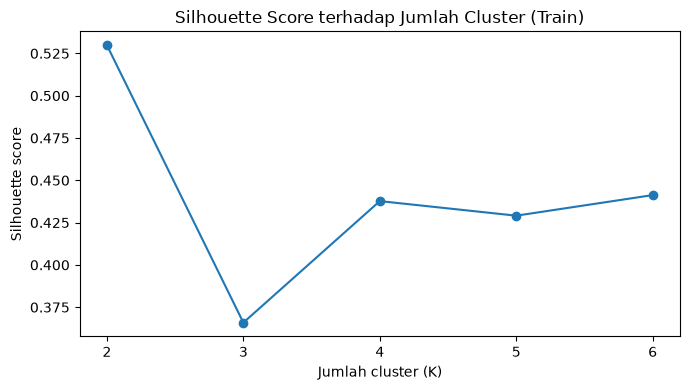

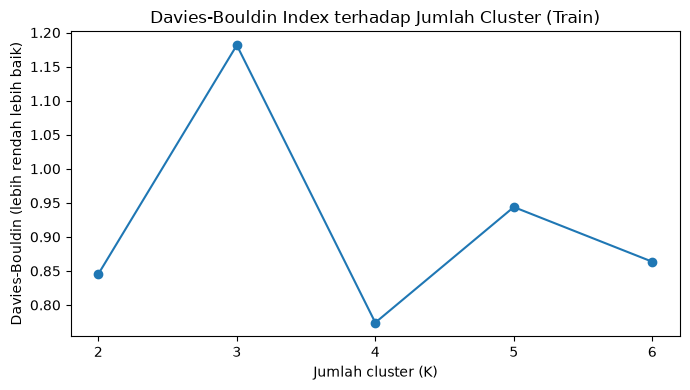

K terpilih berdasarkan silhouette train: 2


In [6]:
plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["silhouette"], marker="o")
plt.title("Silhouette Score terhadap Jumlah Cluster (Train)")
plt.xlabel("Jumlah cluster (K)")
plt.ylabel("Silhouette score")
plt.xticks(scores["k"])
plt.tight_layout()
plt.savefig(OUT / "silhouette_vs_k.png", dpi=180)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["davies_bouldin"], marker="o")
plt.title("Davies-Bouldin Index terhadap Jumlah Cluster (Train)")
plt.xlabel("Jumlah cluster (K)")
plt.ylabel("Davies-Bouldin (lebih rendah lebih baik)")
plt.xticks(scores["k"])
plt.tight_layout()
plt.savefig(OUT / "davies_bouldin_vs_k.png", dpi=180)
plt.show()

best_k = int(scores.loc[scores["silhouette"].idxmax(), "k"])
print("K terpilih berdasarkan silhouette train:", best_k)

## Langkah 6 — Latih model K-Means final pada train

In [7]:
model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10,
    max_iter=300,
)
train_clusters = model.fit_predict(X_train)
test_clusters = model.predict(X_test)

train_counts = pd.Series(train_clusters, name="cluster").value_counts().sort_index()
test_counts = pd.Series(test_clusters, name="cluster").value_counts().sort_index()
print("Jumlah sampel per cluster (train):")
display(train_counts.to_frame("n_samples"))
print("Jumlah sampel per cluster (test):")
display(test_counts.to_frame("n_samples"))

Jumlah sampel per cluster (train):


,n_samples
cluster,
0,1353
1,487


Jumlah sampel per cluster (test):


,n_samples
cluster,
0,335
1,125


## Langkah 7 — Evaluasi data test

K-Means memprediksi ID cluster untuk test tanpa refit. Label test boleh dipakai *setelah* pemilihan K untuk evaluasi eksternal (ARI/NMI), bukan untuk memilih K.

In [8]:
unique_test = np.unique(test_clusters)
if 1 < len(unique_test) < len(X_test):
    test_silhouette = float(silhouette_score(X_test, test_clusters))
    test_db = float(davies_bouldin_score(X_test, test_clusters))
else:
    test_silhouette = None
    test_db = None

ari = float(adjusted_rand_score(y_test, test_clusters))
nmi = float(normalized_mutual_info_score(y_test, test_clusters))
print("Silhouette (test):", test_silhouette)
print("Davies-Bouldin (test):", test_db)
print("ARI dengan label asli (test):", round(ari, 4))
print("NMI dengan label asli (test):", round(nmi, 4))
print("Ingat: cluster bukan label kerusakan otomatis.")

Silhouette (test): 0.5264127855130041
Davies-Bouldin (test): 0.8410875556836359
ARI dengan label asli (test): 0.1375
NMI dengan label asli (test): 0.2412
Ingat: cluster bukan label kerusakan otomatis.


## Langkah 8 — Interpretasi cluster menggunakan label asli

Gunakan label untuk mengetahui komposisi masing-masing cluster. **Jangan mengganti ID cluster dengan nama kelas** tanpa validasi dan pertimbangan ilmiah.

Jumlah sampel menurut cluster dan kelas asli (test):


Kelas asli,Ball,IR,Normal,OR
Cluster,,,,
0,138,105,46,46
1,0,33,0,92


Proporsi kelas per cluster (%):


Kelas asli,Ball,IR,Normal,OR
Cluster,,,,
0,41.2,31.3,13.7,13.7
1,0.0,26.4,0.0,73.6


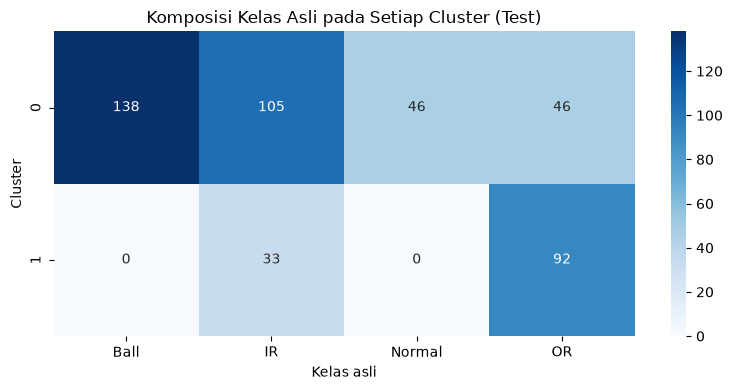

In [9]:
true_names = encoder.inverse_transform(y_test.to_numpy())
composition = pd.crosstab(
    pd.Series(test_clusters, name="Cluster"),
    pd.Series(true_names, name="Kelas asli"),
)
percent = composition.div(composition.sum(axis=1), axis=0).fillna(0) * 100
print("Jumlah sampel menurut cluster dan kelas asli (test):")
display(composition)
print("Proporsi kelas per cluster (%):")
display(percent.round(1))

plt.figure(figsize=(8, 4))
sns.heatmap(composition, annot=True, fmt="d", cmap="Blues")
plt.title("Komposisi Kelas Asli pada Setiap Cluster (Test)")
plt.tight_layout()
plt.savefig(OUT / "cluster_vs_class.png", dpi=180)
plt.show()

## Langkah 9 — Visualisasi PCA 2D

PCA hanya untuk **visualisasi**, bukan bagian dari proses training K-Means atau input API. PCA di-fit pada train, lalu ditransformasikan ke test.

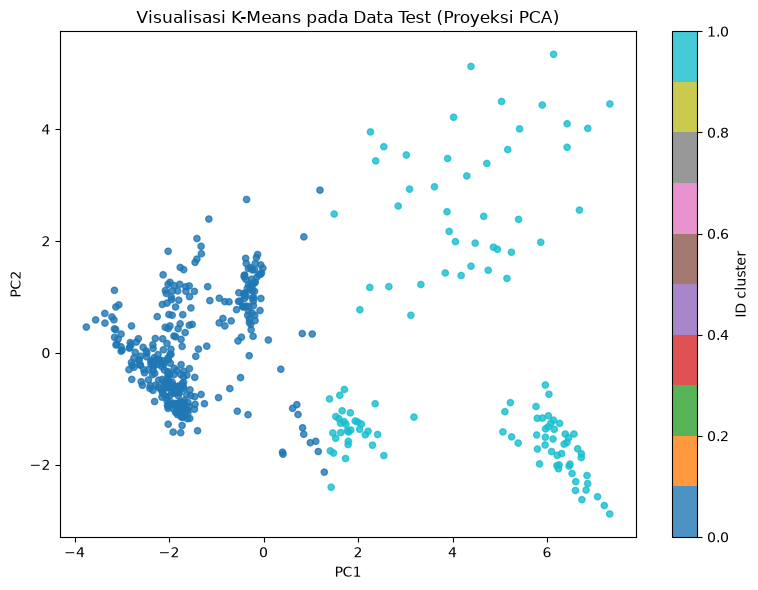

Total explained variance PCA: 0.8053


In [10]:
pca = PCA(n_components=2, random_state=42)
pca.fit(X_train)
X_test_2d = pca.transform(X_test)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_test_2d[:, 0], X_test_2d[:, 1], c=test_clusters,
    cmap="tab10", s=20, alpha=0.8,
)
plt.colorbar(scatter, label="ID cluster")
plt.title("Visualisasi K-Means pada Data Test (Proyeksi PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.savefig(OUT / "clusters_pca.png", dpi=180)
plt.show()
print("Total explained variance PCA:", round(float(pca.explained_variance_ratio_.sum()), 4))

## Langkah 10 — Export model dan metrik

Backend SmartBearing mengharapkan file tepat bernama `models/kmeans_pipeline.pkl`. Model ini menerima **13 fitur yang sudah distandardisasi**; **jangan menambahkan scaler lagi**.

In [11]:
model_path = MODELS_DIR / "kmeans_pipeline.pkl"
joblib.dump(model, model_path)

metrics = {
    "algorithm": "KMeans",
    "trained_on": "13 scaled CWRU features (without label)",
    "selected_k": int(best_k),
    "selection_rule": "max silhouette score on training split",
    "train_silhouette": float(scores.loc[scores["k"] == best_k, "silhouette"].iloc[0]),
    "test_silhouette": test_silhouette,
    "test_davies_bouldin": test_db,
    "test_adjusted_rand_index": ari,
    "test_normalized_mutual_information": nmi,
    "features": features,
    "train_cluster_counts": {str(k): int(v) for k, v in train_counts.items()},
    "test_cluster_counts": {str(k): int(v) for k, v in test_counts.items()},
    "k_candidates": records,
    "limitations": "Random window/row split; not recording-independent evaluation.",
}
with (MODELS_DIR / "metrics_clustering.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print("Model:", model_path)
print("Metrik:", MODELS_DIR / "metrics_clustering.json")

Model: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\models\kmeans_pipeline.pkl
Metrik: c:\Users\Rendy Breventa\MachineLearning\Minggu2\MachineLearning_Kelompok5\MachineLearning-Kelompok-5\models\metrics_clustering.json


## Langkah 11 — Verifikasi model hasil export dan kontrak API Flask

In [12]:
loaded_model = joblib.load(model_path)  # muat hanya model yang dibuat sendiri/tepercaya
sample = X_test.iloc[[0]]
cluster = int(loaded_model.predict(sample)[0])
distances = loaded_model.transform(sample)[0]
assert loaded_model.n_features_in_ == 13
assert len(distances) == loaded_model.n_clusters
assert np.array_equal(loaded_model.predict(X_test), test_clusters)
print("Cluster untuk sampel test pertama:", cluster)
print("Jarak ke centroid setiap cluster:", np.round(distances, 4).tolist())
print("Model siap dipasang ke backend SmartBearing.")

Cluster untuk sampel test pertama: 1
Jarak ke centroid setiap cluster: [10.1985, 5.8098]
Model siap dipasang ke backend SmartBearing.


## Langkah 12 — Uji transformasi input web (opsional tetapi dianjurkan)

Form website menerima **9 fitur dasar** lalu `preprocessing.transform_input` membentuk 13 fitur scaled. Uji alur ini agar input formulir dan model sesuai.

In [13]:
sys.path.insert(0, str(ROOT))
from preprocessing import BASE_FEATURES, transform_input

clean_path = ROOT / "data/processed/cwru_clean.csv"
if clean_path.is_file():
    clean = pd.read_csv(clean_path)
    raw_form = {name: float(clean.iloc[0][name]) for name in BASE_FEATURES}
    scaled_array = transform_input(raw_form, model_dir=MODELS_DIR)
    scaled_frame = pd.DataFrame(scaled_array, columns=features)
    print("Jumlah fitur input web:", len(raw_form))
    print("Jumlah fitur setelah preprocessing:", scaled_frame.shape[1])
    print("Cluster hasil input web:", int(loaded_model.predict(scaled_frame)[0]))
else:
    print("cwru_clean.csv belum ada; lewati cek input web.")

Jumlah fitur input web: 9
Jumlah fitur setelah preprocessing: 13
Cluster hasil input web: 0


## Checklist hasil pekerjaan ML Engineer 2

- [ ] `train_scaled.csv` dan `test_scaled.csv` terbaca, **kolom `label` tidak masuk X**
- [ ] Kandidat K=2–6 dibandingkan menggunakan skor training
- [ ] Model final fit pada training dan dievaluasi pada test
- [ ] Ada grafik `silhouette_vs_k.png`, `davies_bouldin_vs_k.png`, `cluster_vs_class.png`, `clusters_pca.png`
- [ ] Artefak `models/kmeans_pipeline.pkl` terbentuk
- [ ] Artefak `models/metrics_clustering.json` terbentuk
- [ ] Verifikasi `.predict()` dan `.transform()` lulus
- [ ] Uji pada aplikasi Flask (halaman `/unsupervised` dan `/api/status`)

**Push branch khusus unsupervised:** dari root repository jalankan `git switch -c feature/unsupervised`, simpan notebook, `git add training/train_unsupervised.ipynb models/metrics_clustering.json`, commit, push branch, lalu buat Pull Request. **File `.pkl` diabaikan oleh `.gitignore`**; bagikan model terlatih lewat media bersama tepercaya atau ubah kebijakan penyimpanan artefak dengan persetujuan tim.

**Interpretasi ilmiah:** K-Means bukan klasifikasi jenis kerusakan. ID cluster adalah kelompok kemiripan fitur, bukan diagnosis kelas Ball/IR/OR/Normal otomatis.

In [14]:
import pandas as pd
import joblib

# Load data testing
test = pd.read_csv(
    ROOT / "data/processed/test_scaled.csv"
)

# Load model dan encoder
kmeans = joblib.load(
    ROOT / "models/kmeans_pipeline.pkl"
)

encoder = joblib.load(
    ROOT / "models/label_encoder.pkl"
)

# Gunakan urutan fitur yang sama saat training
X_test = test[features]

# Prediksi cluster
clusters = kmeans.predict(X_test)

# Ambil label sebenarnya
labels = encoder.inverse_transform(
    test["label"].astype(int).to_numpy()
)

# Bandingkan label asli dengan cluster
hasil = pd.DataFrame({
    "Kondisi Asli": labels,
    "Cluster": clusters
})

print(pd.crosstab(
    hasil["Kondisi Asli"],
    hasil["Cluster"],
    margins=True
))

Cluster         0    1  All
Kondisi Asli               
Ball          138    0  138
IR            105   33  138
Normal         46    0   46
OR             46   92  138
All           335  125  460
